In [1]:
import sys
from pathlib import Path

# Trỏ đường dẫn tới thư mục src (lùi ra 1 cấp từ notebooks rồi vào src)
src_path = Path.cwd().parent / "src"
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

import pandas as pd
import numpy as np
from figs import *
import warnings; warnings.filterwarnings("ignore")
from nltk.corpus import stopwords
from tfidf_lib import *

## 1. Data loading, profiling

### 1.1 Check 1 - Structure

In [2]:
# quoting=3 is required because many messages contain double quotes.
raw = pd.read_csv("../data/raw/SMSSpamCollection", sep="\t", header=None,
                  names=["label", "text"], encoding="utf-8", quoting=3)
print(raw.shape)
print("\n", raw.dtypes)
print("\n", raw["label"].value_counts())
print("\n", raw["text"].str.contains("£").sum()) # >0 nghĩa là £ đọc đúng

(5574, 2)

 label    str
text     str
dtype: object

 label
ham     4827
spam     747
Name: count, dtype: int64

 258


- **Describe**: File có 5.574 dòng × 2 cột (label, text); mỗi dòng là một tin nhắn.
- **Notice**: Không có cột ID, ngày hay người gửi.
- **Limit**: Không xác định được tin nào cùng người gửi hay cùng thời điểm, nên không kiểm tra được tính độc lập giữa các tin.
- **Check next**: Kiểm tra uniqueness (check 4).

### 1.2 Check 2 - Variable meaning

In [3]:
raw.label.unique() 

<StringArray>
['ham', 'spam']
Length: 2, dtype: str

In [4]:
raw.text

0       Go until jurong point, crazy.. Available only ...
1                           Ok lar... Joking wif u oni...
2       Free entry in 2 a wkly comp to win FA Cup fina...
3       U dun say so early hor... U c already then say...
4       Nah I don't think he goes to usf, he lives aro...
                              ...                        
5569    This is the 2nd time we have tried 2 contact u...
5570                 Will ü b going to esplanade fr home?
5571    Pity, * was in mood for that. So...any other s...
5572    The guy did some bitching but I acted like i'd...
5573                           Rofl. Its true to its name
Name: text, Length: 5574, dtype: str

- **Describe**: `label` chỉ có hai giá trị `ham` và `spam`; `text` là chuỗi thô.
- **Notice**: `label` là biến nhị phân do bộ dữ liệu gán sẵn, không phải đo lường tự động.
- **Limit**: Không biết tiêu chí gán nhãn; có thể có nhiễu nhãn mà ta không phát hiện được.
- **Check next**: Đọc mẫu tin thật ở mỗi lớp (kiểm tra 6).

### 1.3 Check 3 - Completeness

In [5]:
raw.isna().sum()


label    0
text     0
dtype: int64

In [6]:
(raw.text.str.strip()=="").sum()

np.int64(0)

- **Describe**: Số ô thiếu = 0 ở cả hai cột; số tin rỗng sau strip() = 0.
- **Notice**: Không có giá trị thiếu theo nghĩa kỹ thuật.
- **Limit**: Không có NaN không có nghĩa mọi tin đều đầy đủ hay đại diện; tin ngắn như "ok" vẫn hợp lệ nhưng ít thông tin (độ dài nhỏ nhất là 2 ký tự).
- **Check next**: Xem phân phối độ dài ở check 5 và 6.

### 1.4 Check 4 - Uniqueness

In [7]:
raw["key"] = (raw["text"].str.lower().str.strip().str.replace(r"\s+", " ", regex=True))
nlab = raw.groupby("key")["label"].nunique()
conflict = nlab[nlab > 1].index # cùng văn bản, khác nhãn
sizes = raw.groupby("key").size()
print("nhóm trùng:", (sizes > 1).sum(), "| nhóm mâu thuẫn nhãn:", len(conflict))

clean = raw[~raw["key"].isin(conflict)] # loại cả nhóm mâu thuẫn
clean = clean.drop_duplicates(subset="key", keep="first")[["label", "text"]].reset_index(drop=True)
clean.to_csv("../data/processed/sms_dedup.csv", index=False)

raw = raw[["label", "text"]] # corpus gốc, dùng cho sensitivity S1
print(raw.label.value_counts().to_dict(), clean.label.value_counts().to_dict())

nhóm trùng: 290 | nhóm mâu thuẫn nhãn: 0
{'ham': 4827, 'spam': 747} {'ham': 4517, 'spam': 642}


- **Describe**: Có 290 nhóm văn bản trùng (sau lowercase, strip, gộp khoảng trắng) và 0 nhóm mâu thuẫn nhãn. Tập dữ liệu giảm từ 5.574 xuống 5.159 tin: Ham 4.827 → 4.517 (loại 310, tức 6,4%), Spam 747 → 642 (loại 105, tức 14,1%).
- **Notice**: Tỷ lệ trùng ở Spam cao hơn Ham; tỷ lệ Spam giảm từ 13,4% xuống 12,4%.
- **Limit**: Chỉ loại trùng chính xác; near-duplicate (Spam chỉ khác số điện thoại hoặc giải thưởng) vẫn còn, nên P-value và CI có thể vẫn lạc quan.
- **Check next**: Chạy S1 trên corpus gốc để so với tập đã loại trùng; ghi near-duplicate vào Limitations.

### 1.5 Check 5 - Validity

In [8]:
# Kiểm tra độ dài min/max
raw.text.str.len().describe()

count    5574.000000
mean       80.478292
std        59.848302
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: text, dtype: float64

In [9]:
raw.text.str.contains(r"[^\x00-\x7F]").sum() # Số ký tự ngoài ASCII

np.int64(483)

- **Describe**: Độ dài từ 2 đến 910 ký tự (trung vị 62, Q1–Q3 là 36–122). Có 483 tin chứa ký tự ngoài ASCII; 258 tin chứa "£".
- **Notice**: "£" đọc đúng và là ký tự ngoài ASCII, nên ít nhất 258 trong 483 tin đó là do "£". Tin dài nhất (910 ký tự) xa trung vị.
- **Limit**: Chưa phân biệt được các ký tự ngoài ASCII còn lại là ký tự hợp lệ hay lỗi encoding.
- **Check next**: Đọc tin dài nhất và vài tin có ký tự lạ; chạy test 4 (tokenizer giữ "£", số, "!").

### 1.6 Check 6 - Consistency

In [10]:
# Độ dài hai lớp khác nhau thế nào
raw.groupby('label').text.apply(lambda s: s.str.len().median())

label
ham      52.0
spam    149.0
Name: text, dtype: float64

- **Describe**: Độ dài trung vị trên corpus gốc: Ham 52, Spam 149. Sau loại trùng: Ham 53 [34–91], Spam 148 [131–157].
- **Notice**: Tin Spam dài hơn rõ rệt và dải IQR của Spam hẹp (131–157).
- **Limit**: Độ dài ảnh hưởng chuẩn hóa L2, nên trọng số TF-IDF của một term phụ thuộc cả thành phần tin; số liệu này chưa tách được ảnh hưởng đó.
- **Check next**: Vẽ Fig. 3c và đọc lại Δ_int dưới góc nhìn này.

### 1.7 Check 7 - Distribution

In [11]:
# Tỷ lệ Spam (mất cân bằng lớp)
raw.label.value_counts(normalize=True)

label
ham     0.865985
spam    0.134015
Name: proportion, dtype: float64

- **Describe**: Corpus gốc: Ham 86,6%, Spam 13,4%. Sau loại trùng: Ham 4.517, Spam 642 (Spam 12,4%).
- **Notice**: Spam là lớp thiểu số; ngưỡng DF 2% tương ứng ≥ 13 tin Spam và ≥ 91 tin Ham.
- **Limit**: Ước lượng cho Spam kém ổn định hơn Ham; ngưỡng 2% là số tin tuyệt đối khác nhau giữa hai lớp.
- **Check next**: Báo cáo n ở mọi nơi và dùng Wilson CI.

### 1.8 Check 8 – Coverage / timing

- **Describe**: Bộ dữ liệu không có cột ngày, người gửi hay nguồn.
- **Notice**: Không thể phân tích theo thời gian hay theo người gửi.
- **Limit**: Kết quả chỉ phản ánh dataset này (tin tiếng Anh, thu thập khoảng những năm 2000, chủ yếu Anh và Singapore), không khái quát cho SMS spam hiện nay.
- **Check next**: Nêu rõ phạm vi trong Limitations.

### 1.9 Table 1

In [12]:
def summarize(d):
    L = d["text"].str.len(); g = L.groupby(d["label"])
    return pd.DataFrame({"n": d.groupby("label").size(), "median_len": g.median(),
                        "Q1": g.quantile(.25), "Q3": g.quantile(.75)})
    
table1 = pd.concat({"original": summarize(raw), "deduplicated": summarize(clean)})
table1.to_csv("../tables/table1.csv")
print(table1)

                       n  median_len     Q1     Q3
             label                                
original     ham    4827        52.0   33.0   93.0
             spam    747       149.0  133.0  157.0
deduplicated ham    4517        53.0   34.0   91.0
             spam    642       148.0  131.0  157.0


### 1.5 Fig. 1: Class distribution

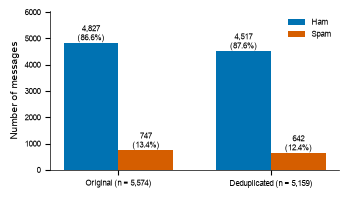

In [13]:
fig = fig1_class_distribution(raw.label.value_counts().to_dict(), clean.label.value_counts().to_dict())
fig.savefig("../figures/fig1_class_distribution.pdf")

## 3. Chạy C2: Mean, DF, Conditional Mean, Δ, phân rã, Top-20 

In [14]:
cfgs = make_configs(stopwords.words("english"))
top, tab = run_analysis(clean, cfgs["C2"], inference=True, return_full=True)
top.to_csv("../tables/top_terms_C2.csv", index=False)
spam = top[top.side == "Spam"]
ham = top[top.side == "Ham"]

In [15]:
print(spam[["term", "DF_S", "DF_H", "m_S", "m_H", "c_S", "c_H", "delta", "d_prev", "d_int", "D", "LPR"]].round(4))


      term    DF_S    DF_H     m_S     m_H     c_S     c_H   delta  d_prev  \
0        £  0.3271  0.0011  0.0471  0.0002  0.1439  0.1985  0.0468  0.0558   
1     call  0.4315  0.0390  0.0487  0.0066  0.1129  0.1686  0.0421  0.0552   
2        !  0.4704  0.1173  0.0529  0.0185  0.1124  0.1573  0.0344  0.0476   
3     free  0.2243  0.0122  0.0358  0.0024  0.1596  0.1949  0.0334  0.0376   
4      txt  0.1916  0.0029  0.0284  0.0005  0.1482  0.1836  0.0279  0.0313   
5       to  0.6231  0.2555  0.0542  0.0273  0.0870  0.1070  0.0269  0.0357   
6     your  0.3146  0.0739  0.0367  0.0118  0.1168  0.1597  0.0249  0.0333   
7     stop  0.1417  0.0073  0.0247  0.0015  0.1741  0.2101  0.0231  0.0258   
8   mobile  0.1495  0.0029  0.0231  0.0006  0.1546  0.2132  0.0225  0.0270   
9        2  0.2134  0.0567  0.0301  0.0090  0.1410  0.1584  0.0211  0.0235   
10    text  0.1433  0.0144  0.0240  0.0029  0.1672  0.1990  0.0211  0.0236   
11   claim  0.1417  0.0000  0.0208  0.0000  0.1464  0.0000  0.02

In [16]:
print(ham[["term", "DF_S", "DF_H", "m_S", "m_H", "c_S", "c_H", "delta", "d_prev", "d_int", "D", "LPR"]].round(4))

     term    DF_S    DF_H     m_S     m_H     c_S     c_H   delta  d_prev  \
20      i  0.0561  0.3465  0.0045  0.0393  0.0794  0.1134 -0.0348 -0.0280   
21     my  0.0187  0.1240  0.0020  0.0183  0.1046  0.1475 -0.0163 -0.0133   
22     me  0.0358  0.1395  0.0037  0.0197  0.1043  0.1409 -0.0159 -0.0127   
23      ?  0.1854  0.2331  0.0172  0.0326  0.0929  0.1398 -0.0154 -0.0056   
24    i'm  0.0109  0.0748  0.0015  0.0138  0.1362  0.1845 -0.0123 -0.0103   
25     it  0.0389  0.1043  0.0043  0.0163  0.1110  0.1561 -0.0120 -0.0087   
26     ok  0.0078  0.0547  0.0011  0.0130  0.1464  0.2376 -0.0118 -0.0090   
27     in  0.0950  0.1516  0.0097  0.0214  0.1023  0.1411 -0.0117 -0.0069   
28    but  0.0093  0.0874  0.0015  0.0128  0.1552  0.1467 -0.0114 -0.0118   
29   that  0.0343  0.0939  0.0036  0.0149  0.1042  0.1592 -0.0114 -0.0079   
30     so  0.0296  0.0868  0.0030  0.0135  0.1027  0.1554 -0.0104 -0.0074   
31     lt  0.0000  0.0496  0.0000  0.0099  0.0000  0.1997 -0.0099 -0.0050   

### 3.2 Đọc tin thật

In [17]:
for t in ["free", "call", "£"]: # đổi thành term của bạn, gồm cả phổ biến lẫn hiếm
    print("=====", t)
    print(show_examples(clean, t, "spam", k=10).to_string())


===== free
                                                                                                                                                                  text
4167             Welcome to UK-mobile-date this msg is FREE giving you free calling to 08719839835. Future mgs billed at 150p daily. To cancel send "go stop" to 89123
3550    Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876
3964     FREEMSG: Our records indicate you may be entitled to 3750 pounds for the Accident you had. To claim for free reply with YES to this msg. To opt out text STOP
1572                                                                                           500 free text msgs. Just text ok to 80488 and we'll credit your account
2585  Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2

### 3.3 Đánh giá H1 (codebook) và H2

In [18]:
# lab = top[["side", "term"]].assign(category="") # điền A/B/C/D/E bằng tay theo codebook
# lab.to_csv("../tables/codebook_labels.csv", index=False)

In [19]:
lab = pd.read_csv("../tables/codebook_labels.csv")
print("Spam:\n", lab[lab.side == "Spam"].category.value_counts()) # H1: số term thuộc A/B/C so với ngưỡng đã đăng ký
print("Ham:\n", lab[lab.side == "Ham"].category.value_counts()) # H1: phía Ham thuộc D
n_prev = (spam.d_prev.abs() > spam.d_int.abs()).sum()
print(f"H2: {n_prev}/20 term Spam có |d_prev| > |d_int| (ngưỡng đã đăng ký: >= 12)")

Spam:
 category
A    8
E    7
C    3
B    2
Name: count, dtype: int64
Ham:
 category
D    10
E     9
C     1
Name: count, dtype: int64
H2: 18/20 term Spam có |d_prev| > |d_int| (ngưỡng đã đăng ký: >= 12)


## 4. Mann–Whitney, Holm, rank-biserial

In [20]:
print(top.columns.tolist())
assert len(top) == 40                     # 20 Spam + 20 Ham
assert (top.p_holm >= top.p_raw - 1e-12).all()   # Holm không bao giờ làm p nhỏ đi
print(top.groupby("side")["r"].describe())       # phía Spam: r > 0; phía Ham: r < 0

['term', 'idf', 'k_S', 'k_H', 'DF_S', 'DF_H', 'm_S', 'm_H', 'c_S', 'c_H', 'delta', 'd_prev', 'd_int', 'D', 'LPR', 'side', 'U', 'p_raw', 'r', 'med_S', 'q1_S', 'q3_S', 'med_H', 'q1_H', 'q3_H', 'p_holm', 'ci_lo_S', 'ci_hi_S', 'ci_lo_H', 'ci_hi_H']
      count      mean       std       min       25%       50%       75%  \
side                                                                      
Ham    20.0 -0.069310  0.059334 -0.301743 -0.068979 -0.054216 -0.045311   
Spam   20.0  0.187645  0.084302  0.093417  0.127696  0.149845  0.216149   

           max  
side            
Ham  -0.008593  
Spam  0.382452  


In [21]:
t3 = top[["side", "term", "p_raw", "p_holm", "r", "D", "LPR"]].copy()
t3["p_holm_fmt"] = t3.p_holm.map(lambda p: "<0.001" if p < 1e-3 else f"{p:.3f}")
t3.to_csv("../tables/table3_inference.csv", index=False)
print("Holm < 0.05:", (top.p_holm < 0.05).sum(), "/ 40")

Holm < 0.05: 39 / 40


## 5. Bốn cấu hình, Jaccard ba góc nhìn, sensitivity S1

### 5.1 Jaccard ba góc nhìn

In [22]:
views = ["all", "unigram", "alpha"] # (i) toàn bộ term; (ii) chỉ unigram; (iii) unigram chỉ chữ cái
tops = {(c, v): run_analysis(clean, cfg, view=v) for c, cfg in cfgs.items() for v in views}
def sets(v, side):
    return {c: tops[(c, v)].query("side == @side")["term"].tolist() for c in cfgs}
J = {(v, s): jaccard_matrix(sets(v, s)) for v in views for s in ("Spam", "Ham")}

for k, M in J.items():
    print(k); print(M.round(2)); M.to_csv(f"../tables/jaccard_{k[0]}_{k[1]}.csv")
# kiểm tra mỗi (cấu hình, góc nhìn, phía) có đủ 20 term; nếu thiếu, ghi lại số thật
print({k: tops[k].groupby("side").size().to_dict() for k in tops})

('all', 'Spam')
      C1    C2    C3    C4
C1  1.00  0.90  0.48  0.48
C2  0.90  1.00  0.43  0.43
C3  0.48  0.43  1.00  0.90
C4  0.48  0.43  0.90  1.00
('all', 'Ham')
      C1    C2    C3    C4
C1  1.00  0.82  0.14  0.14
C2  0.82  1.00  0.14  0.18
C3  0.14  0.14  1.00  0.82
C4  0.14  0.18  0.82  1.00
('unigram', 'Spam')
      C1    C2    C3    C4
C1  1.00  1.00  0.48  0.48
C2  1.00  1.00  0.48  0.48
C3  0.48  0.48  1.00  0.90
C4  0.48  0.48  0.90  1.00
('unigram', 'Ham')
      C1    C2    C3    C4
C1  1.00  0.90  0.14  0.14
C2  0.90  1.00  0.18  0.18
C3  0.14  0.18  1.00  0.90
C4  0.14  0.18  0.90  1.00
('alpha', 'Spam')
      C1    C2    C3    C4
C1  1.00  0.82  0.48  0.48
C2  0.82  1.00  0.43  0.43
C3  0.48  0.43  1.00  0.90
C4  0.48  0.43  0.90  1.00
('alpha', 'Ham')
      C1    C2    C3    C4
C1  1.00  0.90  0.14  0.14
C2  0.90  1.00  0.14  0.14
C3  0.14  0.14  1.00  0.90
C4  0.14  0.14  0.90  1.00
{('C1', 'all'): {'Ham': 20, 'Spam': 20}, ('C1', 'unigram'): {'Ham': 20, 'Spam': 20}, 

góc nhìn (i) thường thấp vì C1/C3 không có bigram, trong khi C2/C4 có: hai danh sách khác
chuỗi dù cùng nội dung. Vì vậy góc nhìn (ii) unigram là cơ sở diễn giải chính; (iii) tách hiệu ứng mất £, !,
số (đưa vào phụ lục). H3: Jaccard Top-20 unigram ≥ 0,5 giữa mọi cặp ở cả hai lớp.

In [23]:
from scipy.stats import spearmanr
top_d, tab_d = run_analysis(clean, cfgs["C2"], inference=True, return_full=True)
top_r, tab_r = run_analysis(raw, cfgs["C2"], inference=True, return_full=True)
for side in ("Spam", "Ham"):
    a = set(top_d.query("side == @side").term); b = set(top_r.query("side == @side").term)
    print(side, "Jaccard Top-20 (dedup vs gốc):", round(len(a & b) / len(a | b), 2))
m = top_d.merge(tab_r[["term", "delta"]], on="term", suffixes=("", "_raw"))
print("tỷ lệ cùng dấu Δ:", (np.sign(m.delta) == np.sign(m.delta_raw)).mean())
both = top_d[["term", "r"]].merge(top_r[["term", "r"]], on="term", suffixes=("_d", "_r"))
print("Spearman rank effect size:", spearmanr(both.r_d, both.r_r))

Spam Jaccard Top-20 (dedup vs gốc): 1.0
Ham Jaccard Top-20 (dedup vs gốc): 0.9
tỷ lệ cùng dấu Δ: 1.0
Spearman rank effect size: SignificanceResult(statistic=np.float64(0.9955461079056586), pvalue=np.float64(1.4776477535403677e-39))


## 6. 

### 6.1 Fig 2, 3, 4

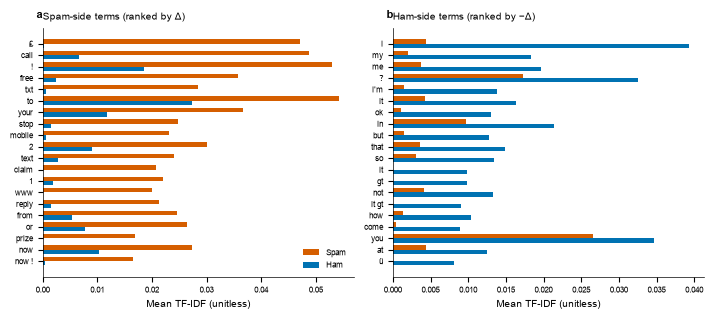

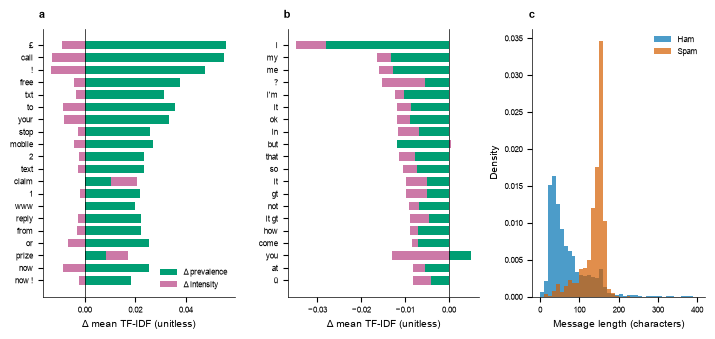

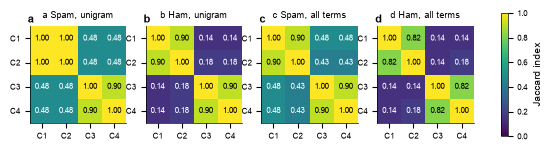

In [24]:
from figs import *
top = pd.read_csv("../tables/top_terms_C2.csv")
L = clean.text.str.len()
fig2_top_terms(top).savefig("../figures/fig2_top_terms.pdf")
fig3_decomposition(top, L[clean.label == "spam"], L[clean.label == "ham"]).savefig("../figures/fig3_decomposition.pdf")
mats = [J[("unigram", "Spam")], J[("unigram", "Ham")], J[("all", "Spam")], J[("all", "Ham")]]
titles = ["a Spam, unigram", "b Ham, unigram", "c Spam, all terms", "d Ham, all terms"]
fig4_jaccard(mats, titles).savefig("../figures/fig4_jaccard.pdf")

### 6.2 Table 2

In [25]:
t2 = top[["side", "term", "m_S", "m_H", "DF_S", "ci_lo_S", "ci_hi_S", "DF_H", "ci_lo_H", "ci_hi_H",
          "c_S", "c_H", "delta", "d_prev", "d_int"]]
t2.to_csv("../tables/table2_top_terms.csv", index=False)